In [4]:
import os
import re
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
from rasterio.mask import mask
from rasterio.windows import from_bounds
from rasterio.features import geometry_mask
from shapely.ops import unary_union
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu
from skimage.feature import graycomatrix, graycoprops
from skimage.color import rgb2gray
from skimage.util import img_as_ubyte
from tqdm import tqdm
import inspect
from imageio import imwrite  # use imageio to write full-resolution PNGs

# Local modules
from indices import veg_index_dict


In [11]:

# --- CONFIGURATION ---
project_name   = "2025_Sijesh_Sugarcane"
hyperspec_path = Path(r"R:\APPF_Data-Q6940\projects_external\2025_Sijesh_Sugarcane\MQN24-32\Gobi\2025-07-16\flight1\2025-07-16-2432-SijeshSugarcane2-corrected.gpro\products\Output\Mosaic_2432_16072025_flight1")
#rgb_path       = Path(r"R:\APPF_Data-Q6940\projects_external\2025_Marcelo_Pasture\GatDairy\M3M\output\Ortho\MS\M3M_13m_Marcelo_Gilbert_Pasture_2025-04-10_10-00-00_M3M_dsm.tif")
shp_path       = Path(r"R:\APPF_Data-Q6940\projects_external\2025_Sijesh_Sugarcane\MQN24-32\ExperimentInfo\plotFile.shp")
id_field       = 'Plot_ID'   # primary plot ID column
id_field2      = 'fid'        # secondary ID column for uniqueness

debug = False
# will process only first 10 plots if debug is True
df = gpd.read_file(shp_path)
max_items = 10 if debug else len(df)

# Output directories
date_str = hyperspec_path.name.split('_')[2].split('.')[0]
# turn date into standard YYYYMMDD format
date_str = f"{date_str[0:4]}{date_str[4:6]}{date_str[6:8]}"
print(date_str)

out_base = Path(project_name) / date_str
out_data = out_base / "data"
out_plots = out_base / "plots"
#out_rgb   = out_data / "rgb_clips"
for d in (out_data, out_plots):
    d.mkdir(parents=True, exist_ok=True)


16072025


In [6]:
# --- OPTIONAL: COPY HYPERSPEC TO LOCAL BUFFER FOR SPEED ---
from pathlib import Path
import shutil
from tqdm import tqdm

copy_to_buffer = True  # set False to read directly from network
buffer_dirname = "_buffer"  # lives under your project/date folder

def copy_file_with_progress(src: Path, dst: Path, chunk_size=16 * 1024 * 1024):
    """Stream-copy with progress; preserves metadata."""
    dst.parent.mkdir(parents=True, exist_ok=True)
    total = src.stat().st_size
    with open(src, "rb") as fsrc, open(dst, "wb") as fdst, tqdm(
        total=total, unit="B", unit_scale=True, unit_divisor=1024,
        desc=f"Copying {src.name}"
    ) as pbar:
        while True:
            buf = fsrc.read(chunk_size)
            if not buf:
                break
            fdst.write(buf)
            pbar.update(len(buf))
    shutil.copystat(src, dst)  # preserve mtime/perm

def same_file_quick(src: Path, dst: Path) -> bool:
    """Quick check: same size & newer/equal mtime at dst."""
    if not dst.exists():
        return False
    s1, s2 = src.stat(), dst.stat()
    return (s1.st_size == s2.st_size) and (s2.st_mtime >= s1.st_mtime)

# Build local project folders (if not already done later)
out_base = Path(project_name) / date_str
out_data = out_base / "data"
out_plots = out_base / "plots"
buffer_dir = out_base / buffer_dirname
for d in (out_data, out_plots, buffer_dir):
    d.mkdir(parents=True, exist_ok=True)

# Decide which hyperspec path to actually use downstream
hyperspec_path_work = hyperspec_path

if copy_to_buffer:
    # Copy the main cube
    local_cube = buffer_dir / hyperspec_path.name
    if not same_file_quick(hyperspec_path, local_cube):
        copy_file_with_progress(hyperspec_path, local_cube)
    else:
        print(f"Local buffer up-to-date: {local_cube}")

    # Copy sidecar files with the same stem (e.g., .hdr, .wvl, .bbl, etc.)
    # This grabs *all* files that share the same stem in the source directory.
    src_stem = hyperspec_path.stem
    for sidecar in hyperspec_path.parent.glob(f"{src_stem}.*"):
        if sidecar.name == hyperspec_path.name:
            continue  # already copied the main .bin
        target = buffer_dir / sidecar.name
        if not same_file_quick(sidecar, target):
            try:
                copy_file_with_progress(sidecar, target)
            except PermissionError:
                # Some tools keep sidecars locked; fall back to copy2
                shutil.copy2(sidecar, target)
                print(f"Copied (no progress) → {target}")
        else:
            print(f"Local sidecar up-to-date: {target}")

    # Switch to local copy for the rest of the pipeline
    hyperspec_path_work = local_cube

print("Using hyperspec file:", hyperspec_path_work)


Copying Mosaic_2432_16072025_flight1: 100%|██████████| 16.5G/16.5G [59:21<00:00, 4.99MB/s]  
Copying Mosaic_2432_16072025_flight1.hdr: 100%|██████████| 7.89k/7.89k [00:00<00:00, 63.2kB/s]

Using hyperspec file: 2025_Sijesh_Sugarcane\16072025\_buffer\Mosaic_2432_16072025_flight1


In [12]:
# --- CRS CHECK ---
import rasterio

with rasterio.open(hyperspec_path_work) as src_crs_chk:
    hs_crs = src_crs_chk.crs
    hs_bounds = src_crs_chk.bounds

print("Hyperspectral CRS:", hs_crs)
print("Hyperspectral bounds:", hs_bounds)
print("Shapefile CRS:", df.crs)

if df.crs != hs_crs:
    print("CRS MISMATCH: Shapefile and hyperspectral raster use different CRSs.")
else:
    print("CRS MATCH: Both layers share the same CRS.")


Hyperspectral CRS: EPSG:28356
Hyperspectral bounds: BoundingBox(left=423923.0907, bottom=7258212.230099999, right=424149.9507, top=7258417.0101)
Shapefile CRS: EPSG:7856
CRS MISMATCH: Shapefile and hyperspectral raster use different CRSs.


Hyperspectral CRS: EPSG:28356
Shapefile CRS: EPSG:7856
⚠️ CRS MISMATCH (no reprojection done for previews).


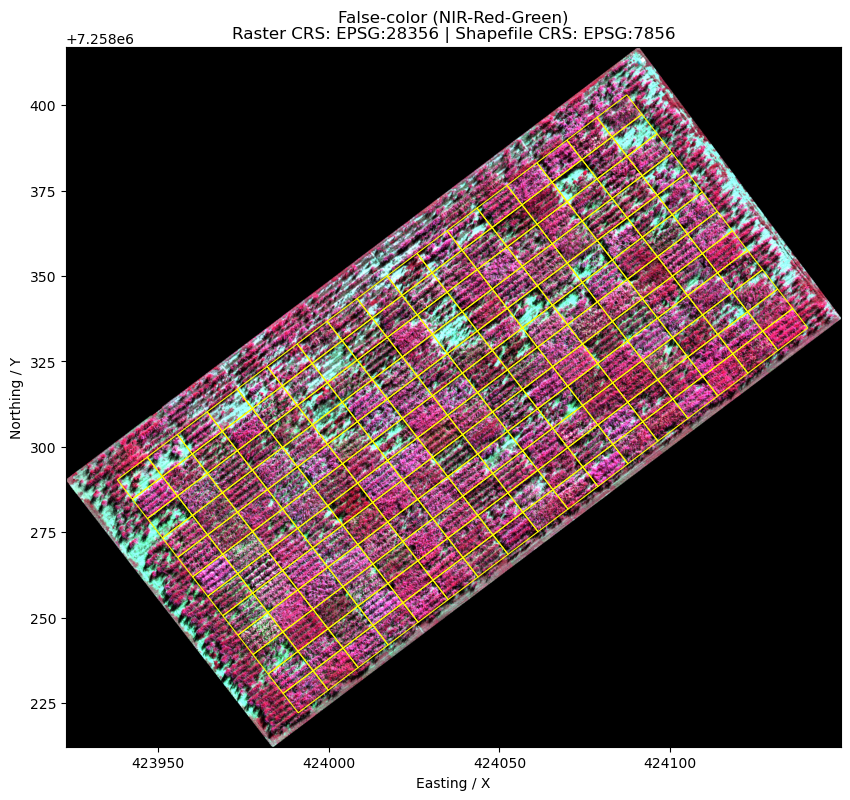

Saved false-color quicklook → 2025_Sijesh_Sugarcane\16072025\plots\falsecolor_16072025.png
Saved OSAVI mask (GeoTIFF) → 2025_Sijesh_Sugarcane\16072025\plots\osavi_mask_16072025.tif
Saved OSAVI (continuous, GeoTIFF) → 2025_Sijesh_Sugarcane\16072025\plots\osavi_16072025.tif
Otsu threshold used: 0.508826


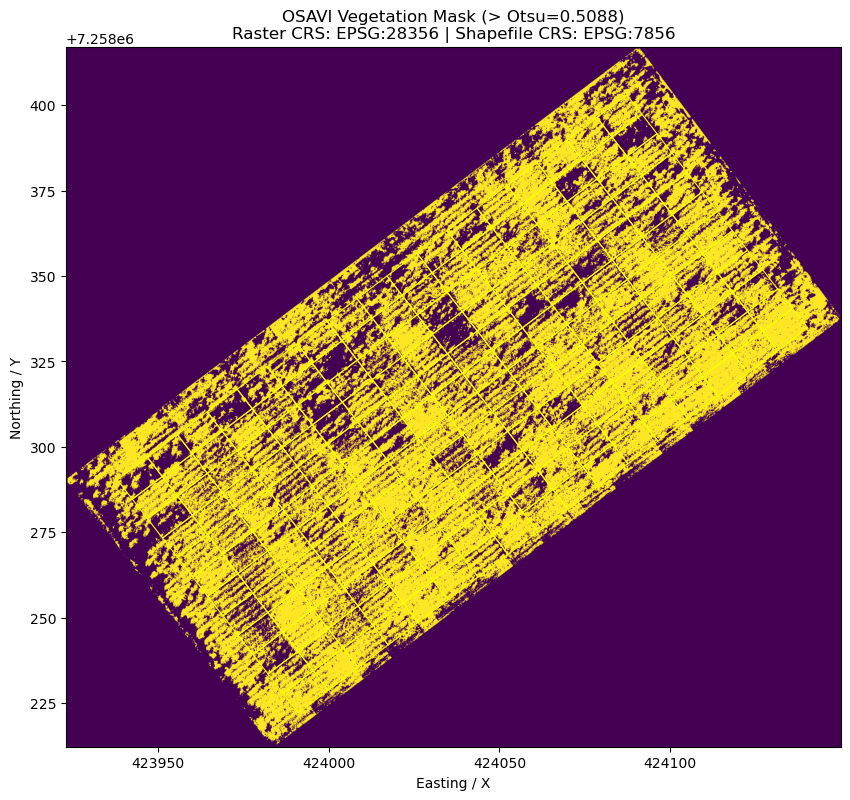

Saved OSAVI mask quicklook (PNG) → 2025_Sijesh_Sugarcane\16072025\plots\osavi_mask_16072025.png


In [ ]:
# --- FALSE-COLOR + OSAVI (single pass, no reprojection) ---
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import array_bounds
from affine import Affine
from skimage.filters import threshold_otsu

out_plots.mkdir(parents=True, exist_ok=True)

# Targets for false color preview
FC_TARGETS_NM = {"nir": 840, "red": 660, "green": 560}  # tweak if needed

def nearest_band_1based(wavelengths, target_nm):
    return int(np.argmin(np.abs(wavelengths - target_nm))) + 1

def percentile_stretch(img, p_low=2, p_high=98):
    lo, hi = np.percentile(img[np.isfinite(img)], [p_low, p_high])
    if hi <= lo:  # fallback
        lo, hi = np.nanmin(img), np.nanmax(img)
        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            lo, hi = 0.0, 1.0
    return np.clip((img - lo) / (hi - lo + 1e-12), 0, 1)

plot_scale = 4  # 1 = full-res (slow). Use 4–10 for faster previews.

with rasterio.open(hyperspec_path_work) as src:
    print("Hyperspectral CRS:", src.crs)
    print("Shapefile CRS:", df.crs)
    if df.crs != src.crs:
        print("CRS MISMATCH (no reprojection done for previews).")

    wavelengths = np.linspace(400, 1000, src.count)

    # ---- FALSE COLOR QUICKLOOK (downsampled) ----
    idx_fc = [
        nearest_band_1based(wavelengths, FC_TARGETS_NM["nir"]),   # R <- NIR
        nearest_band_1based(wavelengths, FC_TARGETS_NM["red"]),   # G <- Red
        nearest_band_1based(wavelengths, FC_TARGETS_NM["green"]), # B <- Green
    ]

    out_h = max(1, src.height // plot_scale)
    out_w = max(1, src.width  // plot_scale)

    fc_small = src.read(
        indexes=idx_fc,
        out_shape=(3, out_h, out_w),
        resampling=Resampling.average
    ).astype("float32")

    # Stretch each channel for display
    R = percentile_stretch(fc_small[0])
    G = percentile_stretch(fc_small[1])
    B = percentile_stretch(fc_small[2])
    fc_rgb = np.dstack([R, G, B])

    # Scaled transform for downsampled previews
    scale_y = src.height / out_h
    scale_x = src.width  / out_w
    transform_scaled = src.transform * Affine.scale(scale_x, scale_y)
    xmin, ymin, xmax, ymax = array_bounds(out_h, out_w, transform_scaled)

    # Plot false color + shapefile
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(fc_rgb, extent=(xmin, xmax, ymin, ymax), origin="upper")
    ax.set_title(f"False-color (NIR-Red-Green)\nRaster CRS: {src.crs} | Shapefile CRS: {df.crs}")
    try:
        df.boundary.plot(ax=ax, facecolor="none", edgecolor="yellow", linewidth=0.8)
    except Exception as e:
        print(f"Could not overlay shapefile on false-color: {e}")
    ax.set_aspect("equal"); ax.set_xlabel("Easting / X"); ax.set_ylabel("Northing / Y")
    falsecolor_png = out_plots / f"falsecolor_{date_str}.png"
    plt.savefig(falsecolor_png, dpi=200, bbox_inches="tight"); plt.show()
    print(f"Saved false-color quicklook → {falsecolor_png}")

    # ---- OSAVI (full-res for outputs, downsampled for preview) ----
    red_nm = veg_index_dict['OSAVI']['bands']['red']
    nir_nm = veg_index_dict['OSAVI']['bands']['nir']
    osavi_fn = veg_index_dict['OSAVI']['formula']

    idx_red = nearest_band_1based(wavelengths, red_nm)
    idx_nir = nearest_band_1based(wavelengths, nir_nm)

    red = src.read(idx_red, masked=True).astype("float32")
    nir = src.read(idx_nir, masked=True).astype("float32")

    valid = ~(red.mask | nir.mask) & np.isfinite(red.data) & np.isfinite(nir.data)
    osavi = np.full(red.shape, np.nan, dtype="float32")
    if valid.any():
        osavi_vals = osavi_fn(nir.data[valid], red.data[valid]).astype("float32")
        osavi[valid] = osavi_vals
    else:
        raise RuntimeError("OSAVI has no valid pixels — check inputs.")

    thr = threshold_otsu(osavi[np.isfinite(osavi)])
    veg_mask = np.zeros(osavi.shape, dtype=np.uint8)
    veg_mask[np.isfinite(osavi)] = (osavi[np.isfinite(osavi)] > thr).astype(np.uint8)

    # Save full-res GeoTIFFs
    mask_tif = out_plots / f"osavi_mask_{date_str}.tif"
    osavi_tif = out_plots / f"osavi_{date_str}.tif"  # continuous

    prof_mask = src.profile.copy()
    prof_mask.update(count=1, dtype="uint8", nodata=0)
    with rasterio.open(mask_tif, "w", **prof_mask) as dst:
        dst.write(veg_mask, 1)

    prof_osavi = src.profile.copy()
    prof_osavi.update(count=1, dtype="float32", nodata=np.float32(np.nan))
    with rasterio.open(osavi_tif, "w", **prof_osavi) as dst:
        dst.write(osavi.astype("float32"), 1)

    print(f"Saved OSAVI mask (GeoTIFF) → {mask_tif}")
    print(f"Saved OSAVI (continuous, GeoTIFF) → {osavi_tif}")
    print(f"Otsu threshold used: {thr:.6f}")

    # Downsampled OSAVI preview (reuse the already-read downsampled red/nir if you want consistency)
    red_small = src.read(idx_red, out_shape=(out_h, out_w), resampling=Resampling.average).astype("float32")
    nir_small = src.read(idx_nir, out_shape=(out_h, out_w), resampling=Resampling.average).astype("float32")
    valid_small = np.isfinite(red_small) & np.isfinite(nir_small)
    osavi_small = np.full((out_h, out_w), np.nan, dtype="float32")
    osavi_small[valid_small] = osavi_fn(nir_small[valid_small], red_small[valid_small]).astype("float32")
    veg_mask_small = np.zeros_like(osavi_small, dtype=bool)
    finite_small = np.isfinite(osavi_small)
    veg_mask_small[finite_small] = osavi_small[finite_small] > thr

# Plot mask preview + shapefile
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(veg_mask_small, extent=(xmin, xmax, ymin, ymax), origin="upper")
ax.set_title(f"OSAVI Vegetation Mask (> Otsu={thr:.4f})\nRaster CRS: {src.crs if 'src' in locals() else 'n/a'} | Shapefile CRS: {df.crs}")
try:
    df.boundary.plot(ax=ax, facecolor="none", edgecolor="yellow", linewidth=0.8)
except Exception as e:
    print(f"Could not overlay shapefile on OSAVI mask: {e}")
ax.set_aspect("equal"); ax.set_xlabel("Easting / X"); ax.set_ylabel("Northing / Y")
mask_png = out_plots / f"osavi_mask_{date_str}.png"
plt.savefig(mask_png, dpi=200, bbox_inches="tight"); plt.show()
print(f"Saved OSAVI mask quicklook (PNG) → {mask_png}")


In [13]:
records, skipped = [], []

with rasterio.open(hyperspec_path_work) as src:
    # 1) real wavelengths if available
    env = src.tags(ns='ENVI')
    if 'wavelength' in env:
        wavelengths = np.array([float(w) for w in env['wavelength'].strip('{}').split(',')])
        if wavelengths.size != src.count:
            wavelengths = np.linspace(400, 1000, src.count)
    else:
        wavelengths = np.linspace(400, 1000, src.count)

    band_labels = [f"r{int(round(wl))}" for wl in wavelengths]
    df = df.to_crs(src.crs) if df.crs != src.crs else df

    # helpers
    def nearest_band_idx(target_nm: float) -> int:
        return int(np.argmin(np.abs(wavelengths - target_nm)))

    red_idx = nearest_band_idx(veg_index_dict['OSAVI']['bands']['red'])
    nir_idx = nearest_band_idx(veg_index_dict['OSAVI']['bands']['nir'])
    osavi_fn = veg_index_dict['OSAVI']['formula']

    for i, (_, row) in enumerate(tqdm(df.iterrows(), total=len(df), desc="Exporting band means")):
        if debug and i >= max_items:
            break

        pid = f"{row[id_field]}_{row[id_field2]}"
        geom = [row.geometry]

        try:
            arr, _ = mask(src, geom, crop=True, all_touched=True, filled=False)  # (B, H, W) masked
        except ValueError:
            skipped.append(pid)
            continue

        # 2) build OSAVI on a common valid footprint
        red = arr[red_idx].astype("float32")
        nir = arr[nir_idx].astype("float32")

        valid = ~(red.mask | nir.mask)
        if not np.any(valid):
            skipped.append(pid)
            continue

        r = red.data.copy()
        n = nir.data.copy()

        # optional autoscale if needed (very rough heuristic)
        if np.nanpercentile(n[valid], 99) > 5 or np.nanpercentile(r[valid], 99) > 5:
            r = r / 10000.0
            n = n / 10000.0

        osavi = np.full(red.shape, np.nan, dtype="float32")
        osavi[valid] = osavi_fn(n[valid], r[valid]).astype("float32")

        finite = np.isfinite(osavi)
        if np.count_nonzero(finite) < 50:  # too few pixels to threshold meaningfully
            osavi_mask_2d = valid  # just use geometry footprint
        else:
            # Otsu with fallback
            vals = osavi[finite]
            try:
                thr = threshold_otsu(vals)
            except Exception:
                thr = 0.2  # fallback
            osavi_mask_2d = np.zeros_like(finite, dtype=bool)
            osavi_mask_2d[finite] = vals > thr
            # ensure we keep something
            if osavi_mask_2d.sum() < 20:
                osavi_mask_2d = valid

        # 3) per-band means using the SAME 2-D mask
        rec = {f"{id_field}_{id_field2}": pid}
        for j, lbl in enumerate(band_labels):
            band = arr[j]
            sel = (~band.mask) & osavi_mask_2d
            if not np.any(sel):
                rec[lbl] = None
            else:
                vals = band.data[sel].astype("float32")
                # optional robust mean to avoid hot pixels
                # p2, p98 = np.percentile(vals, [2, 98])
                # vals = vals[(vals >= p2) & (vals <= p98)]
                rec[lbl] = float(vals.mean()) if vals.size else None

        records.append(rec)

if skipped:
    print(f"Skipped {len(skipped)} plots (no overlap or no valid pixels): {skipped}")

band_means_df = pd.DataFrame(records)
band_means_df.to_csv(out_data / 'band_means.csv', index=False)
print(f"Saved band means → {out_data/'band_means.csv'}")

Exporting band means: 100%|██████████| 204/204 [04:47<00:00,  1.41s/it]


Saved band means → 2025_Sijesh_Sugarcane\16072025\data\band_means.csv


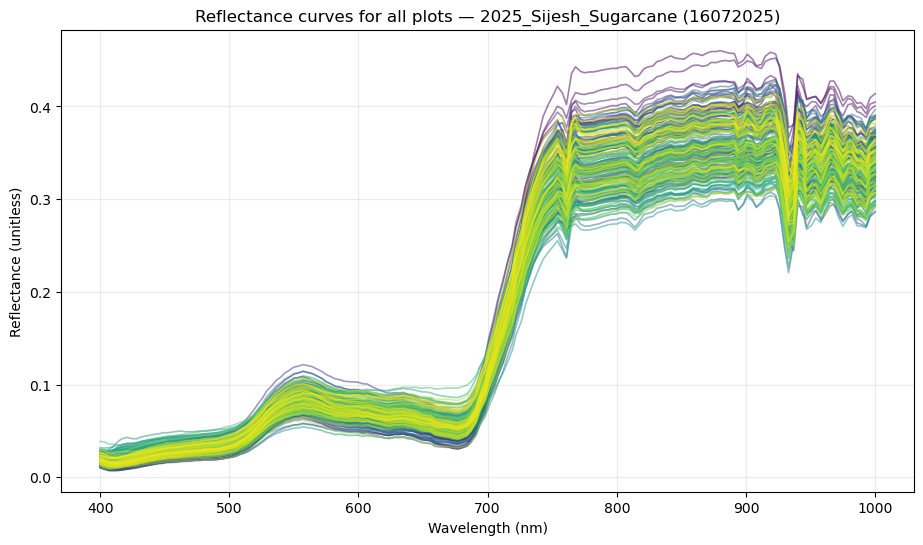

In [14]:
# --- PLOT ALL REFLECTANCE CURVES FROM band_means.csv ---
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = out_data / "band_means.csv"
id_col   = f"{id_field}_{id_field2}" 

# Read CSV
df_means = pd.read_csv(csv_path)

# Find wavelength columns like r560, r661, r842...
wl_cols, wls = [], []
for c in df_means.columns:
    m = re.fullmatch(r"r(\d+)", str(c))
    if m:
        wl_cols.append(c)
        wls.append(int(m.group(1)))
if not wl_cols:
    raise RuntimeError("No wavelength columns found (expected columns like r560, r661, ...).")

# Sort by numeric wavelength
order = np.argsort(wls)
wls_sorted = np.asarray(wls)[order]
cols_sorted = [wl_cols[i] for i in order]

# Values matrix (n_plots x n_bands)
Y = df_means[cols_sorted].to_numpy(dtype=float)

# Global auto-scale to 0..1 if data looks like 0..10000
scale = 10000.0 if np.nanpercentile(Y, 99) > 5 else 1.0
Y_scaled = Y / scale

# Plot
fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.cm.viridis  # "nice" perceptually uniform colormap
n = Y_scaled.shape[0]

for i in range(n):
    y = Y_scaled[i, :]
    valid = np.isfinite(y)
    if valid.sum() < 5:
        continue
    color = cmap(i / max(1, n - 1))
    ax.plot(wls_sorted[valid], y[valid],
            linewidth=1.2, alpha=0.5, color=color)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance (unitless)")
ax.set_title(f"Reflectance curves for all plots — {project_name} ({date_str})")
ax.grid(True, alpha=0.25)

# Optional: if you want OSAVI band markers, uncomment:
# red_nm = veg_index_dict['OSAVI']['bands']['red']
# nir_nm = veg_index_dict['OSAVI']['bands']['nir']
# ax.axvline(red_nm, linestyle="--", linewidth=1)
# ax.axvline(nir_nm, linestyle="--", linewidth=1)

plt.show()


In [23]:
# --- Vegetation indices from per-plot mean reflectances (one column per index) ---
import re
import inspect
import numpy as np
import pandas as pd
from indices import veg_index_dict  # your dictionary of indices

band_means_path = out_data / "band_means.csv"
out_path = out_data / "veg_indices_from_means.csv"

print(f"Loading mean reflectances: {band_means_path}")
df_means = pd.read_csv(band_means_path)
if df_means.empty:
    raise RuntimeError("band_means.csv is empty.")

# Assume the first column is the plot ID (e.g., 'Plot_ID_fid')
plot_id_col = df_means.columns[0]

# Reflectance columns look like r### (e.g., r560)
band_cols = [c for c in df_means.columns if re.fullmatch(r"r\d+", str(c))]
if not band_cols:
    raise RuntimeError("No columns named like r### found in band_means.csv.")

def col_wavelength(c: str) -> int:
    return int(re.findall(r"\d+", c)[0])

available_wls = np.array([col_wavelength(c) for c in band_cols], dtype=float)

def nearest_band_col(target_nm: float, tol_nm: float = 8.0) -> str | None:
    """Return name of the r### column closest to target_nm, or None if outside tolerance."""
    target_nm = float(target_nm)
    idx = int(np.argmin(np.abs(available_wls - target_nm)))
    wl = available_wls[idx]
    col = band_cols[idx]
    return col if abs(wl - target_nm) <= tol_nm else None

# Detect reflectance scale (robust p99 across all r### columns)
p99_all = float(np.nanpercentile(pd.to_numeric(df_means[band_cols].values.ravel(), errors="coerce"), 99))
needs_scale = p99_all > 5.0
print("Detected 0–10000 scale; dividing reflectances by 10000." if needs_scale else "Detected 0–1 reflectance scale.")

# Work on a scaled copy (0–1) so constants like +1 or +0.16 behave correctly
ref = df_means[band_cols].astype("float32").copy()
if needs_scale:
    ref /= 10000.0

# Helper: map a formula parameter to a reflectance Series from 'ref'
def series_for_param(index_name: str, param_name: str) -> pd.Series | None:
    """
    Map a formula parameter to the appropriate reflectance Series in 'ref'.

    Priority:
      1) If param looks like r### (e.g., r531), use that wavelength directly.
      2) Else look up param in veg_index_dict[index_name]['bands'] and use nearest r### column.
      3) If neither applies (e.g., 'eps' default), return None and let caller decide.
    """
    # Explicit r###
    m = re.fullmatch(r"r(\d+)", param_name, flags=re.IGNORECASE)
    if m:
        target = float(m.group(1))
        col = nearest_band_col(target)
        if col is None:
            print(f"Warning: {index_name}: param '{param_name}' (~{target} nm) not found within tolerance.")
            return None
        return ref[col]

    # Semantic name from dict (nir, red, green, red_edge, etc.)
    bands = veg_index_dict[index_name].get("bands", {})
    if param_name in bands:
        target = float(bands[param_name])
        col = nearest_band_col(target)
        if col is None:
            print(f"Warning: {index_name}: param '{param_name}' (~{target} nm) not found within tolerance.")
            return None
        return ref[col]

    # Non-spectral parameter (e.g., 'eps' with default) → None
    return None

print("Computing vegetation indices from mean reflectances...")
index_cols = list(veg_index_dict.keys())
out_df = pd.DataFrame({plot_id_col: df_means[plot_id_col]})

for idx_name, spec in veg_index_dict.items():
    fn = spec["formula"]
    sig = inspect.signature(fn)

    # Build args in parameter order, skipping any with defaults (like eps)
    args = []
    missing_required = False
    for p_name, p_info in sig.parameters.items():
        if p_info.default is not inspect._empty:
            continue  # let function use its default
        s = series_for_param(idx_name, p_name)
        if s is None:
            missing_required = True
            break
        args.append(s.astype("float32"))

    if missing_required:
        out_df[idx_name] = np.nan
        continue

    # Vectorized evaluation over rows
    try:
        vals = fn(*args)
    except Exception as e:
        print(f"Warning: {idx_name} failed to compute ({e}); filling with NaN.")
        vals = np.full(len(out_df), np.nan, dtype="float32")

    vals = np.asarray(vals, dtype="float32")
    vals[~np.isfinite(vals)] = np.nan
    out_df[idx_name] = vals

# Save only Plot ID + indices
out_df.to_csv(out_path, index=False)
print(f"Wrote vegetation indices table -> {out_path}")
print(out_df.head())


Loading mean reflectances: 2025_Sijesh_Sugarcane\16072025\data\band_means.csv
Detected 0–10000 scale; dividing reflectances by 10000.
Computing vegetation indices from mean reflectances...
Wrote vegetation indices table -> 2025_Sijesh_Sugarcane\16072025\data\veg_indices_from_means.csv
  Plot_ID_fid      NDVI     GNDVI   NDVI705       EVI     OSAVI     MCARI  \
0       1_1.0  0.849541  0.693289  0.555900  0.678674  0.636168  0.178952   
1       2_2.0  0.803335  0.678080  0.483781  0.530685  0.563892  0.139924   
2       3_3.0  0.833446  0.678526  0.503391  0.632111  0.618177  0.219219   
3       4_4.0  0.766131  0.603059  0.437812  0.572444  0.562396  0.177892   
4       5_5.0  0.766856  0.670282  0.469995  0.497470  0.536117  0.107398   

      TCARI   CIgreen  CIred-edge       PRI      PSRI      MTCI      NPCI  \
0  0.162133  4.520767    1.988401 -0.099646  0.011279  2.666586  0.387138   
1  0.129802  4.212677    1.515624 -0.115906  0.035850  2.137760  0.444874   
2  0.170214  4.22131

In [ ]:
# --- CLEANUP: REMOVE LOCAL BUFFER COPY (SAFE) ---
import shutil

def delete_local_buffer(buffer_dir: Path, hyperspec_path: Path, confirm: bool = True):
    """
    Deletes the local buffer folder safely.
    Ensures the network source (original hyperspec_path) is never deleted.

    Parameters
    ----------
    buffer_dir : Path
        Local buffer folder (e.g., project/date/_buffer)
    hyperspec_path : Path
        Original network path for the hyperspectral file.
    confirm : bool
        If True, ask user for confirmation before deletion.
    """
    if not buffer_dir.exists():
        print("No buffer directory found — nothing to delete.")
        return

    # Safety checks
    if hyperspec_path.drive.lower() == buffer_dir.drive.lower():
        print("Buffer and network share are on the same drive. Skipping deletion for safety.")
        return
    if "APPF_Data-Q6940" in str(buffer_dir):
        print("Buffer path appears to be on the network — aborting deletion.")
        return
    if buffer_dir.name != "_buffer":
        print(f"Refusing to delete: buffer_dir name is '{buffer_dir.name}', expected '_buffer'.")
        return

    if confirm:
        reply = input(f"Delete local buffer folder '{buffer_dir}'? [y/N]: ").strip().lower()
        if reply != "y":
            print("Skipped buffer deletion.")
            return

    print(f"Deleting local buffer: {buffer_dir}")
    try:
        shutil.rmtree(buffer_dir)
        print("Local buffer deleted successfully.")
    except Exception as e:
        print(f"Could not delete buffer: {e}")

# Call at the end of your pipeline
delete_local_buffer(buffer_dir, hyperspec_path_work)
